In [199]:

import torch
import torch.nn.functional as F

from contextlib import contextmanager
from torch.nn.utils.rnn import pad_sequence
from entmax import entmax_bisect

from transformers import (
    AutoTokenizer,
    Qwen3_5ForConditionalGeneration,
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_ID = "Qwen/Qwen3.5-0.8B"

DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

DTYPE = (
    torch.bfloat16 if DEVICE != "cpu"
    else torch.float32
)

ALPHA = 1.85
BETA = 5
HOPFIELD_STEPS = 4
TOL = 1e-6

LAYER_FRACTION = 0.2
MAX_NEW_TOKENS = 120

texts = [
    "Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.",
    "An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.",
    "Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.",
    "Sunny and warm weather make people happier.",
    "Rainy and cold weather can negatively affect people's mood.",
    "People tend to spend more time outdoors when the weather is pleasant.",
    'Paella is a traditional Valencian dish. The original version is called "Paella Valenciana".',
]

query_text = "What are the main ingredients of Fricandó?"


# ============================================================
# 2. LOAD MODEL
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = Qwen3_5ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
).to(DEVICE).eval()

tokenizer.padding_side = "left"

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

layers = model.model.language_model.layers

num_layers = len(layers)

layer_idx = min(
    int(num_layers * LAYER_FRACTION),
    num_layers - 1,
)

print("Model:", type(model).__name__)
print("Device:", DEVICE)
print("Number of layers:", num_layers)
print("Selected layer:", layer_idx)


# ============================================================
# 3. EXTRACT FULL CONTEXTUAL TOKEN REPRESENTATIONS
# ============================================================

@torch.no_grad()
def extract_representations(texts, layer_idx):
    """
    Extract complete contextual representations at a
    selected transformer layer.

    Each sentence is encoded independently to avoid
    padding effects.

    Returns:
        pooled: [N, D]
            Normalized last-token representations for HFY.

        full_sequences: list of [Li, D]
            Original, unnormalized contextual token states.
    """
    full_sequences = []
    pooled = []

    for text in texts:
        encoded = tokenizer(
            text,
            return_tensors="pt",
            add_special_tokens=False,
        ).to(DEVICE)

        captured = []

        def capture_hook(module, args, output):
            hidden = (
                output[0]
                if isinstance(output, tuple)
                else output
            )
            captured.append(hidden.detach())

        handle = layers[layer_idx].register_forward_hook(
            capture_hook
        )

        try:
            model(
                **encoded,
                use_cache=False,
                return_dict=True,
            )
        finally:
            handle.remove()

        if len(captured) != 1:
            raise RuntimeError(
                f"Expected one capture, got {len(captured)}"
            )

        # [1, Li, D] -> [Li, D]
        hidden = captured[0].squeeze(0).float()

        # Save every token, preserving original magnitudes
        full_sequences.append(hidden.clone())

        # Last-token representation for sentence retrieval
        pooled.append(
            F.normalize(hidden[-1], dim=-1)
        )

    return torch.stack(pooled), full_sequences


# ============================================================
# 4. BUILD MEMORY BANK
# ============================================================

memories, full_memory_sequences = extract_representations(
    texts,
    layer_idx,
)

query_vectors, _ = extract_representations(
    [query_text],
    layer_idx,
)

query = query_vectors.squeeze(0)

print("\nMEMORY BANK")
print("Sentence vectors:", memories.shape)
print("Query vector:", query.shape)

for i, sequence in enumerate(full_memory_sequences):
    print(f"Memory {i} token states:", sequence.shape)


# ============================================================
# 5. HOPFIELD-FENCHEL-YOUNG RETRIEVAL
# ============================================================

def hopfield_retrieve(
    query,
    memories,
    alpha=1.5,
    beta=8.0,
    steps=20,
    tol=1e-6,
):
    """
    HFY fixed-point retrieval with alpha-entmax.

    Returns:
        state: [D]
        weights: [N]
        trajectory: [iterations + 1, D]
    """
    if not 1.0 <= alpha <= 2.0:
        raise ValueError("alpha must be in [1, 2]")

    M = F.normalize(memories.float(), dim=-1)
    state = F.normalize(query.float(), dim=-1)

    trajectory = [state.clone()]

    def compute_weights(current_state):
        scores = beta * (M @ current_state)

        if alpha == 1.0:
            return F.softmax(scores, dim=0)

        return entmax_bisect(
            scores,
            alpha=alpha,
            dim=0,
            n_iter=50,
        )

    for _ in range(steps):
        weights = compute_weights(state)
        new_state = weights @ M

        delta = torch.linalg.vector_norm(
            new_state - state
        )

        state = new_state
        trajectory.append(state.clone())

        if delta.item() < tol:
            break

    weights = compute_weights(state)

    return state, weights, torch.stack(trajectory)


with torch.no_grad():
    retrieved_state, weights, trajectory = hopfield_retrieve(
        query,
        memories,
        alpha=ALPHA,
        beta=BETA,
        steps=HOPFIELD_STEPS,
        tol=TOL,
    )

print("\nHFY RETRIEVAL")

for i in torch.argsort(weights, descending=True).tolist():
    print(f"{weights[i].item():.6f} | {texts[i]}")

print("Iterations:", len(trajectory) - 1)


# ============================================================
# 6. WEIGHTED TOKEN-LEVEL MEMORY
# ============================================================

def compose_weighted_memory(
    full_sequences,
    weights,
):
    """
    Weighted composition of full contextual token states.

    H_retrieved[j] = sum_i weights[i] * H_i[j]

    Sentences are left-aligned by token position and
    zero-padded to a common sequence length.

    Args:
        full_sequences:
            List of N tensors [Li, D]

        weights:
            HFY probabilities [N]

    Returns:
        retrieved_tokens:
            [1, max(Li), D]
    """
    if len(full_sequences) != weights.numel():
        raise ValueError(
            "Number of sequences and weights must match"
        )

    # [N, Lmax, D], with zeros after shorter sequences
    padded_memories = pad_sequence(
        full_sequences,
        batch_first=True,
        padding_value=0.0,
    ).float()

    weights = weights.to(
        device=padded_memories.device,
        dtype=padded_memories.dtype,
    )

    # Weighted sum over stored sentences
    retrieved_tokens = torch.einsum(
        "n,nld->ld",
        weights,
        padded_memories,
    )

    # [Lmax, D] -> [1, Lmax, D]
    return retrieved_tokens.unsqueeze(0)

print(full_memory_sequences.shape)
retrieved_memory_tokens = compose_weighted_memory(
    full_memory_sequences,
    weights,
)

print("\nWEIGHTED TOKEN MEMORY")
print("Shape:", retrieved_memory_tokens.shape)

# With N=1, this must equal the original token sequence
if len(texts) == 1:
    torch.testing.assert_close(
        retrieved_memory_tokens.squeeze(0),
        full_memory_sequences[0],
    )
    print("Verified: full token memory preserved exactly.")


# ============================================================
# 7. PREPARE QUERY WITH RESERVED MEMORY POSITIONS
# ============================================================

def make_prompt(question):
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


def prepare_inputs(question, num_memory_tokens=0):
    encoded = tokenizer(
        make_prompt(question),
        return_tensors="pt",
        add_special_tokens=False,
    ).to(DEVICE)

    if num_memory_tokens == 0:
        return encoded

    prefix_ids = torch.full(
        (1, num_memory_tokens),
        tokenizer.eos_token_id,
        dtype=torch.long,
        device=DEVICE,
    )

    input_ids = torch.cat(
        [prefix_ids, encoded["input_ids"]],
        dim=1,
    )

    return {
        "input_ids": input_ids,
        "attention_mask": torch.ones_like(input_ids),
    }


# ============================================================
# 8. INJECT FULL WEIGHTED TOKEN MEMORY
# ============================================================

@contextmanager
def prepend_memory_at_layer(
    layer_idx,
    memory_tokens,
):
    """
    Replace reserved prefix positions at the output
    of layer_idx with weighted full-token memory states.

    memory_tokens: [1, M, D]

    No pooling, normalization, or rescaling is performed.
    Query token states are not directly modified.
    """
    injected = False

    def hook(module, args, output):
        nonlocal injected

        if injected:
            return output

        hidden = (
            output[0]
            if isinstance(output, tuple)
            else output
        )

        memory = memory_tokens.detach().to(
            device=hidden.device,
            dtype=hidden.dtype,
        )

        if memory.ndim != 3:
            raise ValueError("Expected [1, M, D] memory")

        B, M, D = memory.shape

        if B != 1 or hidden.shape[0] != 1:
            raise ValueError("Only batch size 1 is supported")

        if hidden.shape[1] <= M:
            raise ValueError("No query positions found")

        if hidden.shape[-1] != D:
            raise ValueError("Hidden dimension mismatch")

        # Preserve query positions from the same layer.
        query_hidden = hidden[:, M:, :]

        # [memory tokens] + [query tokens]
        modified = torch.cat(
            [memory, query_hidden],
            dim=1,
        )

        print("\nINJECTION")
        print("Memory:", memory.shape)
        print("Query:", query_hidden.shape)
        print("Combined:", modified.shape)

        injected = True

        if isinstance(output, tuple):
            return (modified, *output[1:])

        return modified

    handle = layers[layer_idx].register_forward_hook(hook)

    try:
        yield
    finally:
        handle.remove()

        if not injected:
            raise RuntimeError("Memory injection not triggered")


# ============================================================
# 9. GENERATION
# ============================================================

@torch.no_grad()
def generate_answer(
    question,
    memory_tokens=None,
    reserve_positions=False,
):
    M = (
        memory_tokens.shape[1]
        if memory_tokens is not None
        else (
            retrieved_memory_tokens.shape[1]
            if reserve_positions else 0
        )
    )

    inputs = prepare_inputs(
        question,
        num_memory_tokens=M,
    )

    kwargs = {
        **inputs,
        "max_new_tokens": MAX_NEW_TOKENS,
        "do_sample": False,
        "use_cache": True,
        "pad_token_id": tokenizer.pad_token_id,
        "temperature": 0.0,
    }

    if memory_tokens is None:
        generated = model.generate(**kwargs)
    else:
        with prepend_memory_at_layer(
            layer_idx,
            memory_tokens,
        ):
            generated = model.generate(**kwargs)

    new_tokens = generated[
        0, inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()


# ============================================================
# 10. RUN EXPERIMENTS
# ============================================================

torch.manual_seed(30)

random_memory_tokens = torch.randn_like(
    retrieved_memory_tokens
)

# Match random control's overall tensor norm
random_memory_tokens = (
    random_memory_tokens
    / random_memory_tokens.norm().clamp_min(1e-12)
    * retrieved_memory_tokens.norm()
)

zero_memory_tokens = torch.zeros_like(
    retrieved_memory_tokens
)

best_idx = weights.argmax().item()

experiments = {
    "BASELINE": lambda: generate_answer(
        query_text
    ),

    "RESERVED TOKEN CONTROL": lambda: generate_answer(
        query_text,
        reserve_positions=True,
    ),

    "HFY WEIGHTED TOKEN MEMORY": lambda: generate_answer(
        query_text,
        memory_tokens=retrieved_memory_tokens,
    ),

    "RANDOM MEMORY CONTROL": lambda: generate_answer(
        query_text,
        memory_tokens=random_memory_tokens,
    ),

    "ZERO MEMORY CONTROL": lambda: generate_answer(
        query_text,
        memory_tokens=zero_memory_tokens,
    ),

    "TEXT RETRIEVAL": lambda: generate_answer(
        f"Context: {texts[best_idx]}\n\n"
        f"Question: {query_text}\n"
        "Answer using the provided context."
    ),
}

results = {}

for name, experiment in experiments.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    results[name] = experiment()
    print(results[name])


# ============================================================
# 11. SUMMARY
# ============================================================

print("\nEXPERIMENT SUMMARY")
print("Model:", MODEL_ID)
print("Layer:", layer_idx, "/", num_layers)
print("Alpha:", ALPHA)
print("Beta:", BETA)
print("Number of memories:", len(texts))
print("HFY weights:", weights.tolist())
print("Token memory shape:", retrieved_memory_tokens.shape)
print("HFY iterations:", len(trajectory) - 1)


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 22719.43it/s]


Model: Qwen3_5ForConditionalGeneration
Device: mps
Number of layers: 24
Selected layer: 4

MEMORY BANK
Sentence vectors: torch.Size([7, 1024])
Query vector: torch.Size([1024])
Memory 0 token states: torch.Size([38, 1024])
Memory 1 token states: torch.Size([23, 1024])
Memory 2 token states: torch.Size([37, 1024])
Memory 3 token states: torch.Size([9, 1024])
Memory 4 token states: torch.Size([12, 1024])
Memory 5 token states: torch.Size([13, 1024])
Memory 6 token states: torch.Size([22, 1024])

HFY RETRIEVAL
0.402095 | Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.
0.326253 | Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.
0.271651 | An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.
0.000000 | Sunny and warm weather make 

AttributeError: 'list' object has no attribute 'shape'

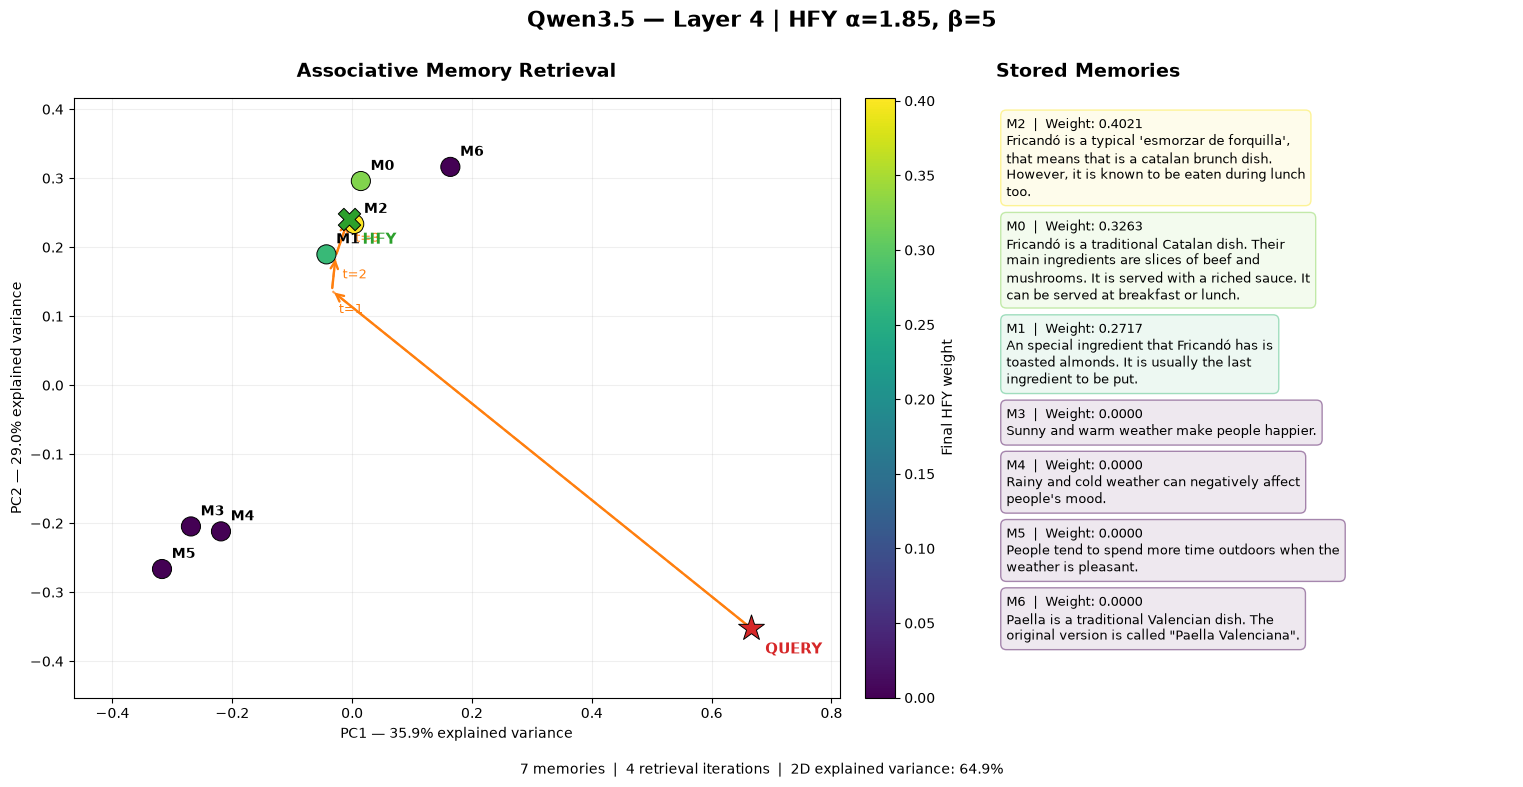

In [194]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from textwrap import fill


def plot_memory_pca(
    memories,
    query,
    retrieved_state,
    trajectory,
    texts,
    weights=None,
    figsize=(16, 8),
):
    """
    Two-panel HFY visualization:
      Left: PCA with query, memories and retrieval trajectory.
      Right: Memory descriptions and final HFY weights.

    PCA is fitted only on memories and the initial query.
    """

    def to_numpy(tensor):
        return tensor.detach().float().cpu().numpy()

    M = to_numpy(memories)
    q = to_numpy(query).reshape(1, -1)
    s = to_numpy(retrieved_state).reshape(1, -1)
    T = to_numpy(trajectory)

    N = len(texts)

    if N != len(M):
        raise ValueError("Number of texts and memories differ")

    # --------------------------------------------------------
    # 1. Fit PCA on original memories and query
    # --------------------------------------------------------

    fit_vectors = np.concatenate([M, q], axis=0)

    pca = PCA(n_components=2)
    pca.fit(fit_vectors)

    memory_2d = pca.transform(M)
    query_2d = pca.transform(q)[0]
    retrieved_2d = pca.transform(s)[0]
    trajectory_2d = pca.transform(T)

    probabilities = (
        to_numpy(weights)
        if weights is not None
        else np.zeros(N)
    )

    # --------------------------------------------------------
    # 2. Create figure
    # --------------------------------------------------------

    fig, (ax, ax_info) = plt.subplots(
        1,
        2,
        figsize=figsize,
        gridspec_kw={"width_ratios": [1.6, 1]},
    )

    fig.subplots_adjust(
        left=0.07,
        right=0.97,
        top=0.87,
        bottom=0.12,
        wspace=0.14,
    )

    # --------------------------------------------------------
    # 3. Plot memories
    # --------------------------------------------------------

    points = ax.scatter(
        memory_2d[:, 0],
        memory_2d[:, 1],
        c=probabilities,
        cmap="viridis",
        vmin=0,
        vmax=max(0.1, probabilities.max()),
        s=190,
        edgecolors="black",
        linewidths=0.7,
        zorder=4,
    )

    # Small ID labels instead of sentence text
    for i, (x, y) in enumerate(memory_2d):
        ax.annotate(
            f"M{i}",
            xy=(x, y),
            xytext=(7, 8),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold",
            zorder=7,
        )

    # --------------------------------------------------------
    # 4. Plot retrieval trajectory
    # --------------------------------------------------------

    ax.plot(
        trajectory_2d[:, 0],
        trajectory_2d[:, 1],
        linestyle="--",
        linewidth=1.5,
        color="tab:orange",
        alpha=0.75,
        zorder=2,
    )

    # Arrows showing update direction
    for step in range(len(trajectory_2d) - 1):
        start = trajectory_2d[step]
        end = trajectory_2d[step + 1]

        if np.linalg.norm(end - start) < 1e-5:
            continue

        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops={
                "arrowstyle": "->",
                "color": "tab:orange",
                "lw": 1.7,
                "mutation_scale": 13,
            },
            zorder=3,
        )

    # Number intermediate iterations only
    for step, (x, y) in enumerate(trajectory_2d[1:-1], 1):
        ax.annotate(
            f"t={step}",
            (x, y),
            xytext=(5, -16),
            textcoords="offset points",
            fontsize=9,
            color="tab:orange",
        )

    # --------------------------------------------------------
    # 5. Query and final state
    # --------------------------------------------------------

    ax.scatter(
        *query_2d,
        marker="*",
        s=380,
        color="tab:red",
        edgecolors="black",
        linewidths=0.7,
        zorder=8,
    )

    ax.annotate(
        "QUERY",
        query_2d,
        xytext=(10, -18),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="tab:red",
    )

    ax.scatter(
        *retrieved_2d,
        marker="X",
        s=260,
        color="tab:green",
        edgecolors="black",
        linewidths=0.7,
        zorder=9,
    )

    ax.annotate(
        "HFY",
        retrieved_2d,
        xytext=(10, -18),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="tab:green",
    )

    # --------------------------------------------------------
    # 6. Format PCA axes
    # --------------------------------------------------------

    explained = pca.explained_variance_ratio_

    ax.set_xlabel(
        f"PC1 — {explained[0]:.1%} explained variance"
    )
    ax.set_ylabel(
        f"PC2 — {explained[1]:.1%} explained variance"
    )

    ax.set_title(
        "Associative Memory Retrieval",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )

    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

    ax.margins(0.15)

    colorbar = fig.colorbar(
        points,
        ax=ax,
        fraction=0.045,
        pad=0.03,
    )
    colorbar.set_label("Final HFY weight")

    # --------------------------------------------------------
    # 7. Right panel: memory descriptions
    # --------------------------------------------------------

    ax_info.axis("off")

    ax_info.set_title(
        "Stored Memories",
        fontsize=14,
        fontweight="bold",
        loc="left",
        pad=15,
    )

    sorted_ids = np.argsort(-probabilities)

    rows = [
        (
            f"M{i}  |  Weight: {probabilities[i]:.4f}\n"
            f"{fill(texts[i], width=48)}"
        )
        for i in sorted_ids
    ]

    # Dynamically size each text block according to length
    total_lines = sum(row.count("\n") + 1 for row in rows)
    line_step = 0.91 / max(total_lines + N, 1)

    y = 0.97

    for i, row_text in zip(sorted_ids, rows):
        lines = row_text.count("\n") + 1
        color = plt.cm.viridis(
            probabilities[i] / max(probabilities.max(), 0.1)
        )

        ax_info.text(
            0.02,
            y,
            row_text,
            transform=ax_info.transAxes,
            fontsize=9,
            va="top",
            linespacing=1.35,
            bbox={
                "boxstyle": "round,pad=0.45",
                "facecolor": (*color[:3], 0.09),
                "edgecolor": (*color[:3], 0.45),
            },
        )

        y -= line_step * (lines + 1)

    # --------------------------------------------------------
    # 8. Global title and summary
    # --------------------------------------------------------

    fig.suptitle(
        f"Qwen3.5 — Layer {layer_idx} | "
        f"HFY α={ALPHA}, β={BETA}",
        fontsize=16,
        fontweight="bold",
    )

    fig.text(
        0.5,
        0.025,
        f"{N} memories  |  "
        f"{len(T) - 1} retrieval iterations  |  "
        f"2D explained variance: {explained.sum():.1%}",
        ha="center",
        fontsize=10,
    )

    plt.show()

    return pca


pca = plot_memory_pca(
    memories=memories,
    query=query,
    retrieved_state=retrieved_state,
    trajectory=trajectory,
    texts=texts,
    weights=weights,
)


In [200]:

import torch
import torch.nn.functional as F

from contextlib import contextmanager
from torch.nn.utils.rnn import pad_sequence
from entmax import entmax_bisect

from transformers import (
    AutoTokenizer,
    Qwen3_5ForConditionalGeneration,
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_ID = "Qwen/Qwen3.5-0.8B"

DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

DTYPE = (
    torch.bfloat16 if DEVICE != "cpu"
    else torch.float32
)

ALPHA = 2
BETA = 5
HOPFIELD_STEPS = 4
TOL = 1e-6

LAYER_FRACTION = 0.2
MAX_NEW_TOKENS = 120

texts = [
    "Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.",
    "An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.",
    "Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.",
    "Sunny and warm weather make people happier.",
    "Rainy and cold weather can negatively affect people's mood.",
    "People tend to spend more time outdoors when the weather is pleasant.",
    'Paella is a traditional Valencian dish. The original version is called "Paella Valenciana".',
]

query_text = "What are the main ingredients of Fricandó?"


# ============================================================
# 2. LOAD MODEL
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = Qwen3_5ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
).to(DEVICE).eval()

tokenizer.padding_side = "left"

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

layers = model.model.language_model.layers

num_layers = len(layers)

layer_idx = min(
    int(num_layers * LAYER_FRACTION),
    num_layers - 1,
)

print("Model:", type(model).__name__)
print("Device:", DEVICE)
print("Number of layers:", num_layers)
print("Selected layer:", layer_idx)


# ============================================================
# 3. EXTRACT FULL CONTEXTUAL TOKEN REPRESENTATIONS
# ============================================================

@torch.no_grad()
def extract_representations(texts, layer_idx):
    """
    Extract complete contextual representations at a
    selected transformer layer.

    Each sentence is encoded independently to avoid
    padding effects.

    Returns:
        pooled: [N, D]
            Normalized last-token representations for HFY.

        full_sequences: list of [Li, D]
            Original, unnormalized contextual token states.
    """
    full_sequences = []
    pooled = []

    for text in texts:
        encoded = tokenizer(
            text,
            return_tensors="pt",
            add_special_tokens=False,
        ).to(DEVICE)

        captured = []

        def capture_hook(module, args, output):
            hidden = (
                output[0]
                if isinstance(output, tuple)
                else output
            )
            captured.append(hidden.detach())

        handle = layers[layer_idx].register_forward_hook(
            capture_hook
        )

        try:
            model(
                **encoded,
                use_cache=False,
                return_dict=True,
            )
        finally:
            handle.remove()

        if len(captured) != 1:
            raise RuntimeError(
                f"Expected one capture, got {len(captured)}"
            )

        # [1, Li, D] -> [Li, D]
        hidden = captured[0].squeeze(0).float()

        # Save every token, preserving original magnitudes
        full_sequences.append(hidden.clone())

        # Last-token representation for sentence retrieval
        pooled.append(
            F.normalize(hidden[-1], dim=-1)
        )

    return torch.stack(pooled), full_sequences


# ============================================================
# 4. BUILD MEMORY BANK
# ============================================================

memories, full_memory_sequences = extract_representations(
    texts,
    layer_idx,
)

query_vectors, _ = extract_representations(
    [query_text],
    layer_idx,
)

query = query_vectors.squeeze(0)

print("\nMEMORY BANK")
print("Sentence vectors:", memories.shape)
print("Query vector:", query.shape)

for i, sequence in enumerate(full_memory_sequences):
    print(f"Memory {i} token states:", sequence.shape)


# ============================================================
# 5. HOPFIELD-FENCHEL-YOUNG RETRIEVAL
# ============================================================

def hopfield_retrieve(
    query,
    memories,
    alpha=1.5,
    beta=8.0,
    steps=20,
    tol=1e-6,
):
    """
    HFY fixed-point retrieval with alpha-entmax.

    Returns:
        state: [D]
        weights: [N]
        trajectory: [iterations + 1, D]
    """
    if not 1.0 <= alpha <= 2.0:
        raise ValueError("alpha must be in [1, 2]")

    M = F.normalize(memories.float(), dim=-1)
    state = F.normalize(query.float(), dim=-1)

    trajectory = [state.clone()]

    def compute_weights(current_state):
        scores = beta * (M @ current_state)

        if alpha == 1.0:
            return F.softmax(scores, dim=0)

        return entmax_bisect(
            scores,
            alpha=alpha,
            dim=0,
            n_iter=50,
        )

    for _ in range(steps):
        weights = compute_weights(state)
        new_state = weights @ M

        delta = torch.linalg.vector_norm(
            new_state - state
        )

        state = new_state
        trajectory.append(state.clone())

        if delta.item() < tol:
            break

    weights = compute_weights(state)

    return state, weights, torch.stack(trajectory)


with torch.no_grad():
    retrieved_state, weights, trajectory = hopfield_retrieve(
        query,
        memories,
        alpha=ALPHA,
        beta=BETA,
        steps=HOPFIELD_STEPS,
        tol=TOL,
    )

print("\nHFY RETRIEVAL")

for i in torch.argsort(weights, descending=True).tolist():
    print(f"{weights[i].item():.6f} | {texts[i]}")

print("Iterations:", len(trajectory) - 1)


# ============================================================
# 6. WEIGHTED TOKEN-LEVEL MEMORY
# ============================================================

def compose_weighted_memory(
    full_sequences,
    weights,
):
    """
    Weighted composition of full contextual token states.

    H_retrieved[j] = sum_i weights[i] * H_i[j]

    Sentences are left-aligned by token position and
    zero-padded to a common sequence length.

    Args:
        full_sequences:
            List of N tensors [Li, D]

        weights:
            HFY probabilities [N]

    Returns:
        retrieved_tokens:
            [1, max(Li), D]
    """
    if len(full_sequences) != weights.numel():
        raise ValueError(
            "Number of sequences and weights must match"
        )

    # [N, Lmax, D], with zeros after shorter sequences
    padded_memories = pad_sequence(
        full_sequences,
        batch_first=True,
        padding_value=0.0,
    ).float()

    weights = weights.to(
        device=padded_memories.device,
        dtype=padded_memories.dtype,
    )

    # Weighted sum over stored sentences
    retrieved_tokens = torch.einsum(
        "n,nld->ld",
        weights,
        padded_memories,
    )

    # [Lmax, D] -> [1, Lmax, D]
    return retrieved_tokens.unsqueeze(0)


retrieved_memory_tokens = compose_weighted_memory(
    full_memory_sequences,
    weights,
)

print("\nWEIGHTED TOKEN MEMORY")
print("Shape:", retrieved_memory_tokens.shape)

# With N=1, this must equal the original token sequence
if len(texts) == 1:
    torch.testing.assert_close(
        retrieved_memory_tokens.squeeze(0),
        full_memory_sequences[0],
    )
    print("Verified: full token memory preserved exactly.")


# ============================================================
# 7. PREPARE QUERY WITH RESERVED MEMORY POSITIONS
# ============================================================

def make_prompt(question):
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


def prepare_inputs(question, num_memory_tokens=0):
    encoded = tokenizer(
        make_prompt(question),
        return_tensors="pt",
        add_special_tokens=False,
    ).to(DEVICE)

    if num_memory_tokens == 0:
        return encoded

    prefix_ids = torch.full(
        (1, num_memory_tokens),
        tokenizer.eos_token_id,
        dtype=torch.long,
        device=DEVICE,
    )

    input_ids = torch.cat(
        [prefix_ids, encoded["input_ids"]],
        dim=1,
    )

    return {
        "input_ids": input_ids,
        "attention_mask": torch.ones_like(input_ids),
    }


# ============================================================
# 8. INJECT FULL WEIGHTED TOKEN MEMORY
# ============================================================

@contextmanager
def prepend_memory_at_layer(
    layer_idx,
    memory_tokens,
):
    """
    Replace reserved prefix positions at the output
    of layer_idx with weighted full-token memory states.

    memory_tokens: [1, M, D]

    No pooling, normalization, or rescaling is performed.
    Query token states are not directly modified.
    """
    injected = False

    def hook(module, args, output):
        nonlocal injected

        if injected:
            return output

        hidden = (
            output[0]
            if isinstance(output, tuple)
            else output
        )

        memory = memory_tokens.detach().to(
            device=hidden.device,
            dtype=hidden.dtype,
        )

        if memory.ndim != 3:
            raise ValueError("Expected [1, M, D] memory")

        B, M, D = memory.shape

        if B != 1 or hidden.shape[0] != 1:
            raise ValueError("Only batch size 1 is supported")

        if hidden.shape[1] <= M:
            raise ValueError("No query positions found")

        if hidden.shape[-1] != D:
            raise ValueError("Hidden dimension mismatch")

        # Preserve query positions from the same layer.
        query_hidden = hidden[:, M:, :]

        # [memory tokens] + [query tokens]
        modified = torch.cat(
            [memory, query_hidden],
            dim=1,
        )

        print("\nINJECTION")
        print("Memory:", memory.shape)
        print("Query:", query_hidden.shape)
        print("Combined:", modified.shape)

        injected = True

        if isinstance(output, tuple):
            return (modified, *output[1:])

        return modified

    handle = layers[layer_idx].register_forward_hook(hook)

    try:
        yield
    finally:
        handle.remove()

        if not injected:
            raise RuntimeError("Memory injection not triggered")


# ============================================================
# 9. GENERATION
# ============================================================

@torch.no_grad()
def generate_answer(
    question,
    memory_tokens=None,
    reserve_positions=False,
):
    M = (
        memory_tokens.shape[1]
        if memory_tokens is not None
        else (
            retrieved_memory_tokens.shape[1]
            if reserve_positions else 0
        )
    )

    inputs = prepare_inputs(
        question,
        num_memory_tokens=M,
    )

    kwargs = {
        **inputs,
        "max_new_tokens": MAX_NEW_TOKENS,
        "do_sample": False,
        "use_cache": True,
        "pad_token_id": tokenizer.pad_token_id,
        "temperature": 0.0,
    }

    if memory_tokens is None:
        generated = model.generate(**kwargs)
    else:
        with prepend_memory_at_layer(
            layer_idx,
            memory_tokens,
        ):
            generated = model.generate(**kwargs)

    new_tokens = generated[
        0, inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()


# ============================================================
# 10. RUN EXPERIMENTS
# ============================================================

torch.manual_seed(30)

random_memory_tokens = torch.randn_like(
    retrieved_memory_tokens
)

# Match random control's overall tensor norm
random_memory_tokens = (
    random_memory_tokens
    / random_memory_tokens.norm().clamp_min(1e-12)
    * retrieved_memory_tokens.norm()
)

zero_memory_tokens = torch.zeros_like(
    retrieved_memory_tokens
)

best_idx = weights.argmax().item()

experiments = {
    "BASELINE": lambda: generate_answer(
        query_text
    ),

    "RESERVED TOKEN CONTROL": lambda: generate_answer(
        query_text,
        reserve_positions=True,
    ),

    "HFY WEIGHTED TOKEN MEMORY": lambda: generate_answer(
        query_text,
        memory_tokens=retrieved_memory_tokens,
    ),

    "RANDOM MEMORY CONTROL": lambda: generate_answer(
        query_text,
        memory_tokens=random_memory_tokens,
    ),

    "ZERO MEMORY CONTROL": lambda: generate_answer(
        query_text,
        memory_tokens=zero_memory_tokens,
    ),

    "TEXT RETRIEVAL": lambda: generate_answer(
        f"Context: {texts[best_idx]}\n\n"
        f"Question: {query_text}\n"
        "Answer using the provided context."
    ),
}

results = {}

for name, experiment in experiments.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    results[name] = experiment()
    print(results[name])


# ============================================================
# 11. SUMMARY
# ============================================================

print("\nEXPERIMENT SUMMARY")
print("Model:", MODEL_ID)
print("Layer:", layer_idx, "/", num_layers)
print("Alpha:", ALPHA)
print("Beta:", BETA)
print("Number of memories:", len(texts))
print("HFY weights:", weights.tolist())
print("Token memory shape:", retrieved_memory_tokens.shape)
print("HFY iterations:", len(trajectory) - 1)


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 18565.64it/s]


Model: Qwen3_5ForConditionalGeneration
Device: mps
Number of layers: 24
Selected layer: 4

MEMORY BANK
Sentence vectors: torch.Size([7, 1024])
Query vector: torch.Size([1024])
Memory 0 token states: torch.Size([38, 1024])
Memory 1 token states: torch.Size([23, 1024])
Memory 2 token states: torch.Size([37, 1024])
Memory 3 token states: torch.Size([9, 1024])
Memory 4 token states: torch.Size([12, 1024])
Memory 5 token states: torch.Size([13, 1024])
Memory 6 token states: torch.Size([22, 1024])

HFY RETRIEVAL
0.424305 | Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.
0.330110 | Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.
0.245585 | An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.
0.000000 | Sunny and warm weather make 

In [201]:
memories

tensor([[-3.3758e-01,  9.0424e-03,  1.2691e-03,  ..., -1.4753e-02,
         -2.2210e-03,  4.4022e-03],
        [-3.1014e-01,  1.6696e-02, -6.6459e-02,  ..., -2.4597e-02,
         -1.5312e-02,  8.7961e-03],
        [-3.1758e-01,  3.7915e-02, -3.2730e-02,  ..., -1.7661e-02,
         -1.1423e-02, -1.2395e-02],
        ...,
        [-2.8434e-01,  1.3682e-02, -7.1085e-02,  ..., -1.9501e-02,
         -3.1454e-04,  1.4075e-02],
        [-1.5236e-01,  7.5577e-03, -5.4718e-02,  ..., -4.3079e-03,
         -4.0811e-03,  2.1464e-02],
        [-1.9632e-01, -8.3869e-03, -8.1384e-02,  ..., -2.5937e-02,
          8.7364e-04,  2.1744e-02]], device='mps:0')

In [198]:

import torch
import torch.nn.functional as F

from contextlib import contextmanager
from torch.nn.utils.rnn import pad_sequence
from entmax import entmax_bisect

from transformers import (
    AutoTokenizer,
    Qwen3_5ForConditionalGeneration,
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_ID = "Qwen/Qwen3.5-0.8B"

DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

DTYPE = (
    torch.bfloat16 if DEVICE != "cpu"
    else torch.float32
)

ALPHA = 1
BETA = 5
HOPFIELD_STEPS = 4
TOL = 1e-6

LAYER_FRACTION = 0.2
MAX_NEW_TOKENS = 120

texts = [
    "Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.",
    "An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.",
    "Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.",
    "Sunny and warm weather make people happier.",
    "Rainy and cold weather can negatively affect people's mood.",
    "People tend to spend more time outdoors when the weather is pleasant.",
    'Paella is a traditional Valencian dish. The original version is called "Paella Valenciana".',
]

query_text = "What are the main ingredients of Fricandó?"


# ============================================================
# 2. LOAD MODEL
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = Qwen3_5ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
).to(DEVICE).eval()

tokenizer.padding_side = "left"

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

layers = model.model.language_model.layers

num_layers = len(layers)

layer_idx = min(
    int(num_layers * LAYER_FRACTION),
    num_layers - 1,
)

print("Model:", type(model).__name__)
print("Device:", DEVICE)
print("Number of layers:", num_layers)
print("Selected layer:", layer_idx)


# ============================================================
# 3. EXTRACT FULL CONTEXTUAL TOKEN REPRESENTATIONS
# ============================================================

@torch.no_grad()
def extract_representations(texts, layer_idx):
    """
    Extract complete contextual representations at a
    selected transformer layer.

    Each sentence is encoded independently to avoid
    padding effects.

    Returns:
        pooled: [N, D]
            Normalized last-token representations for HFY.

        full_sequences: list of [Li, D]
            Original, unnormalized contextual token states.
    """
    full_sequences = []
    pooled = []

    for text in texts:
        encoded = tokenizer(
            text,
            return_tensors="pt",
            add_special_tokens=False,
        ).to(DEVICE)

        captured = []

        def capture_hook(module, args, output):
            hidden = (
                output[0]
                if isinstance(output, tuple)
                else output
            )
            captured.append(hidden.detach())

        handle = layers[layer_idx].register_forward_hook(
            capture_hook
        )

        try:
            model(
                **encoded,
                use_cache=False,
                return_dict=True,
            )
        finally:
            handle.remove()

        if len(captured) != 1:
            raise RuntimeError(
                f"Expected one capture, got {len(captured)}"
            )

        # [1, Li, D] -> [Li, D]
        hidden = captured[0].squeeze(0).float()

        # Save every token, preserving original magnitudes
        full_sequences.append(hidden.clone())

        # Last-token representation for sentence retrieval
        pooled.append(
            F.normalize(hidden[-1], dim=-1)
        )

    return torch.stack(pooled), full_sequences


# ============================================================
# 4. BUILD MEMORY BANK
# ============================================================

memories, full_memory_sequences = extract_representations(
    texts,
    layer_idx,
)

query_vectors, _ = extract_representations(
    [query_text],
    layer_idx,
)

query = query_vectors.squeeze(0)

print("\nMEMORY BANK")
print("Sentence vectors:", memories.shape)
print("Query vector:", query.shape)

for i, sequence in enumerate(full_memory_sequences):
    print(f"Memory {i} token states:", sequence.shape)


# ============================================================
# 5. HOPFIELD-FENCHEL-YOUNG RETRIEVAL
# ============================================================

def hopfield_retrieve(
    query,
    memories,
    alpha=1.5,
    beta=8.0,
    steps=20,
    tol=1e-6,
):
    """
    HFY fixed-point retrieval with alpha-entmax.

    Returns:
        state: [D]
        weights: [N]
        trajectory: [iterations + 1, D]
    """
    if not 1.0 <= alpha <= 2.0:
        raise ValueError("alpha must be in [1, 2]")

    M = F.normalize(memories.float(), dim=-1)
    state = F.normalize(query.float(), dim=-1)

    trajectory = [state.clone()]

    def compute_weights(current_state):
        scores = beta * (M @ current_state)

        if alpha == 1.0:
            return F.softmax(scores, dim=0)

        return entmax_bisect(
            scores,
            alpha=alpha,
            dim=0,
            n_iter=50,
        )

    for _ in range(steps):
        weights = compute_weights(state)
        new_state = weights @ M

        delta = torch.linalg.vector_norm(
            new_state - state
        )

        state = new_state
        trajectory.append(state.clone())

        if delta.item() < tol:
            break

    weights = compute_weights(state)

    return state, weights, torch.stack(trajectory)


with torch.no_grad():
    retrieved_state, weights, trajectory = hopfield_retrieve(
        query,
        memories,
        alpha=ALPHA,
        beta=BETA,
        steps=HOPFIELD_STEPS,
        tol=TOL,
    )

print("\nHFY RETRIEVAL")

for i in torch.argsort(weights, descending=True).tolist():
    print(f"{weights[i].item():.6f} | {texts[i]}")

print("Iterations:", len(trajectory) - 1)


# ============================================================
# 6. WEIGHTED TOKEN-LEVEL MEMORY
# ============================================================

def compose_weighted_memory(
        query,
    full_sequences,
    weights,
):
    """
    Weighted composition of full contextual token states.

    H_retrieved[j] = sum_i weights[i] * H_i[j]

    Sentences are left-aligned by token position and
    zero-padded to a common sequence length.

    Args:
        full_sequences:
            List of N tensors [Li, D]

        weights:
            HFY probabilities [N]

    Returns:
        retrieved_tokens:
            [1, max(Li), D]
    """
    if len(full_sequences) != weights.numel():
        raise ValueError(
            "Number of sequences and weights must match"
        )

    # [N, Lmax, D], with zeros after shorter sequences
    padded_memories = pad_sequence(
        full_sequences,
        batch_first=True,
        padding_value=0.0,
    ).float()

    weights = weights.to(
        device=padded_memories.device,
        dtype=padded_memories.dtype,
    )

    # Weighted sum over stored sentences
    print(query.shape, padded_memories.shape, weights.shape)
    retrieved_tokens = torch.einsum(
        "n,nld->ld",
        weights,
        padded_memories,
    )

    # [Lmax, D] -> [1, Lmax, D]
    return retrieved_tokens.unsqueeze(0)


retrieved_memory_tokens = compose_weighted_memory(
    query,
    full_memory_sequences,
    weights,
)

print("\nWEIGHTED TOKEN MEMORY")
print("Shape:", retrieved_memory_tokens.shape)

# With N=1, this must equal the original token sequence
if len(texts) == 1:
    torch.testing.assert_close(
        retrieved_memory_tokens.squeeze(0),
        full_memory_sequences[0],
    )
    print("Verified: full token memory preserved exactly.")


# ============================================================
# 7. PREPARE QUERY WITH RESERVED MEMORY POSITIONS
# ============================================================

def make_prompt(question):
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


def prepare_inputs(question, num_memory_tokens=0):
    encoded = tokenizer(
        make_prompt(question),
        return_tensors="pt",
        add_special_tokens=False,
    ).to(DEVICE)

    if num_memory_tokens == 0:
        return encoded

    prefix_ids = torch.full(
        (1, num_memory_tokens),
        tokenizer.eos_token_id,
        dtype=torch.long,
        device=DEVICE,
    )

    input_ids = torch.cat(
        [prefix_ids, encoded["input_ids"]],
        dim=1,
    )

    return {
        "input_ids": input_ids,
        "attention_mask": torch.ones_like(input_ids),
    }


# ============================================================
# 8. INJECT FULL WEIGHTED TOKEN MEMORY
# ============================================================

@contextmanager
def prepend_memory_at_layer(
    layer_idx,
    memory_tokens,
):
    """
    Replace reserved prefix positions at the output
    of layer_idx with weighted full-token memory states.

    memory_tokens: [1, M, D]

    No pooling, normalization, or rescaling is performed.
    Query token states are not directly modified.
    """
    injected = False

    def hook(module, args, output):
        nonlocal injected

        if injected:
            return output

        hidden = (
            output[0]
            if isinstance(output, tuple)
            else output
        )

        memory = memory_tokens.detach().to(
            device=hidden.device,
            dtype=hidden.dtype,
        )

        if memory.ndim != 3:
            raise ValueError("Expected [1, M, D] memory")

        B, M, D = memory.shape

        if B != 1 or hidden.shape[0] != 1:
            raise ValueError("Only batch size 1 is supported")

        if hidden.shape[1] <= M:
            raise ValueError("No query positions found")

        if hidden.shape[-1] != D:
            raise ValueError("Hidden dimension mismatch")

        # Preserve query positions from the same layer.
        query_hidden = hidden[:, M:, :]

        # [memory tokens] + [query tokens]
        modified = torch.cat(
            [memory, query_hidden],
            dim=1,
        )

        print("\nINJECTION")
        print("Memory:", memory.shape)
        print("Query:", query_hidden.shape)
        print("Combined:", modified.shape)

        injected = True

        if isinstance(output, tuple):
            return (modified, *output[1:])

        return modified

    handle = layers[layer_idx].register_forward_hook(hook)

    try:
        yield
    finally:
        handle.remove()

        if not injected:
            raise RuntimeError("Memory injection not triggered")


# ============================================================
# 9. GENERATION
# ============================================================

@torch.no_grad()
def generate_answer(
    question,
    memory_tokens=None,
    reserve_positions=False,
):
    M = (
        memory_tokens.shape[1]
        if memory_tokens is not None
        else (
            retrieved_memory_tokens.shape[1]
            if reserve_positions else 0
        )
    )

    inputs = prepare_inputs(
        question,
        num_memory_tokens=M,
    )

    kwargs = {
        **inputs,
        "max_new_tokens": MAX_NEW_TOKENS,
        "do_sample": False,
        "use_cache": True,
        "pad_token_id": tokenizer.pad_token_id,
        "temperature": 0.0,
    }

    if memory_tokens is None:
        generated = model.generate(**kwargs)
    else:
        with prepend_memory_at_layer(
            layer_idx,
            memory_tokens,
        ):
            generated = model.generate(**kwargs)

    new_tokens = generated[
        0, inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()


# ============================================================
# 10. RUN EXPERIMENTS
# ============================================================

torch.manual_seed(30)

random_memory_tokens = torch.randn_like(
    retrieved_memory_tokens
)

# Match random control's overall tensor norm
random_memory_tokens = (
    random_memory_tokens
    / random_memory_tokens.norm().clamp_min(1e-12)
    * retrieved_memory_tokens.norm()
)

zero_memory_tokens = torch.zeros_like(
    retrieved_memory_tokens
)

best_idx = weights.argmax().item()

experiments = {
    "BASELINE": lambda: generate_answer(
        query_text
    ),

    "RESERVED TOKEN CONTROL": lambda: generate_answer(
        query_text,
        reserve_positions=True,
    ),

    "HFY WEIGHTED TOKEN MEMORY": lambda: generate_answer(
        query_text,
        memory_tokens=retrieved_memory_tokens,
    ),

    "RANDOM MEMORY CONTROL": lambda: generate_answer(
        query_text,
        memory_tokens=random_memory_tokens,
    ),

    "ZERO MEMORY CONTROL": lambda: generate_answer(
        query_text,
        memory_tokens=zero_memory_tokens,
    ),

    "TEXT RETRIEVAL": lambda: generate_answer(
        f"Context: {texts[best_idx]}\n\n"
        f"Question: {query_text}\n"
        "Answer using the provided context."
    ),
}

results = {}

for name, experiment in experiments.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    results[name] = experiment()
    print(results[name])


# ============================================================
# 11. SUMMARY
# ============================================================

print("\nEXPERIMENT SUMMARY")
print("Model:", MODEL_ID)
print("Layer:", layer_idx, "/", num_layers)
print("Alpha:", ALPHA)
print("Beta:", BETA)
print("Number of memories:", len(texts))
print("HFY weights:", weights.tolist())
print("Token memory shape:", retrieved_memory_tokens.shape)
print("HFY iterations:", len(trajectory) - 1)


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 19762.77it/s]


Model: Qwen3_5ForConditionalGeneration
Device: mps
Number of layers: 24
Selected layer: 4

MEMORY BANK
Sentence vectors: torch.Size([7, 1024])
Query vector: torch.Size([1024])
Memory 0 token states: torch.Size([38, 1024])
Memory 1 token states: torch.Size([23, 1024])
Memory 2 token states: torch.Size([37, 1024])
Memory 3 token states: torch.Size([9, 1024])
Memory 4 token states: torch.Size([12, 1024])
Memory 5 token states: torch.Size([13, 1024])
Memory 6 token states: torch.Size([22, 1024])

HFY RETRIEVAL
0.165502 | Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.
0.154964 | An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.
0.152815 | Rainy and cold weather can negatively affect people's mood.
0.148645 | Sunny and warm weather make people happier.
0.147937 | Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef an

In [208]:
memories.shape, full_memory_sequences[2].shape

(torch.Size([7, 1024]), torch.Size([37, 1024]))